# 2. Boiling point: Chemprop graph neural network

**Workshop goal:** build and assess a compact, reproducible graph-neural-network model that predicts boiling point from a molecule's SMILES string. Chemprop converts each SMILES string into a molecular graph, learns directed bond messages, pools the learned graph representation, and predicts a boiling point.

[![Overview of the Chemprop directed message-passing architecture](https://oscarwumit.github.io/images/chemprop.png)](https://doi.org/10.1021/acs.jcim.3c01250)

*Figure 1. Overview of the Chemprop architecture, from [Heid et al., 2024](https://doi.org/10.1021/acs.jcim.3c01250). The D-MPNN converts atom and bond information into a molecular representation, which a feed-forward network maps to the target property.*

## Workshop workflow

1. Set the workshop run parameters and load the boiling-point data.
2. Use SMILES as the model input and boiling point as the prediction target.
3. Create reproducible training, validation, and held-out test sets.
4. Train a directed message-passing neural network (D-MPNN) with learning-rate scheduling and early stopping.
5. Identify the model from the lowest validation-loss epoch, evaluate it on the held-out test set, and predict a new molecule.

This random split is appropriate for a workshop demonstration. For a claim about performance on new chemical families, participants should next consider a scaffold- or group-aware split. Cross-validation and uncertainty ensembles are intentionally left out so the independent test set stays untouched and the exercise remains CPU-sized.

## Key Chemprop references

1. [Yang et al. (2019), *Analyzing Learned Molecular Representations for Property Prediction*](https://doi.org/10.1021/acs.jcim.9b00237) — foundational directed message-passing model and evaluation study.
2. [Heid et al. (2024), *Chemprop: A Machine Learning Package for Chemical Property Prediction*](https://doi.org/10.1021/acs.jcim.3c01250) — Chemprop architecture and software capabilities.
3. [Graff et al. (2026), *Chemprop v2: An Efficient, Modular Machine Learning Package for Chemical Property Prediction*](https://doi.org/10.1021/acs.jcim.5c02332) — the modern Chemprop v2 implementation used in this workshop.


### Reading and presenting this notebook

The bullet points above each code cell explain what to notice; saved outputs remain visible. In **VS Code**, open the Command Palette (`Ctrl+Shift+P` on Windows/Linux, `Cmd+Shift+P` on macOS) and choose **Notebook: Collapse All Cell Inputs** (search for `Collapse All Cell Inputs`). Use **Expand All Cell Inputs** to edit, or expand an individual cell using its input control. Do not collapse outputs. VS Code can remember your previous view, so use the command if code is still shown. In **JupyterLab**, code inputs are initially hidden via notebook metadata; expand them with the left-hand cell collapser or the View menu. Hiding code does not disable execution or remove it from the file.


**What to notice**

- Load boiling points in kelvin and make reproducible molecular train/validation/test splits shared with the foundation-model demo.
- Only SMILES supplies input features; depth controls message-passing steps and hidden dimension controls vector width.
- Review the architecture, 20-epoch segments, and learning-rate settings before starting the longer training cell.


In [1]:
from pathlib import Path
from importlib.metadata import version
import json
import shutil, subprocess, sys, tempfile, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, Image, display
from rdkit import Chem
from rdkit.Chem import Draw
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split


def persistent_progress(label, completed, total):
    """Render one static progress bar after a processing stage finishes."""
    percent = 100 * completed / max(total, 1)
    display(HTML(f'<div style="margin:0.35rem 0"><strong>{label}</strong><br>'
                 f'<progress value="{completed}" max="{total}" style="width:22rem"></progress> '
                 f'{completed}/{total} ({percent:.0f}%)</div>'))


# 1. Reproducible experiment configuration
SEED = 42
SAMPLE_SIZE = 4600       # Set to a larger value for a more representative workshop run.
MAX_EPOCHS = 2000        # Safety cap; segmented training can stop earlier when it has converged.
CHUNK_EPOCHS = 20       # Each Chemprop invocation trains this many epochs before reassessment.
VALIDATION_SLOPE_WINDOW = 20
TRIMMED_SLOPE_EXCLUDED_POINTS = 5
BATCH_SIZE = 64
DEPTH = 3
MESSAGE_HIDDEN_DIM = 300
FFN_HIDDEN_DIM = 64
FFN_NUM_LAYERS = 3
DROPOUT = 0.01
ACTIVATION = 'RELU'
LOSS_FUNCTION = 'mse'
METRICS = ['mae', 'rmse', 'r2']
# Chemprop's Noam-like schedule runs inside each 20-epoch weight-transfer segment.
WARMUP_EPOCHS, INIT_LR, MAX_LR, FINAL_LR = 3, 1e-5, 1e-5, 1e-5
ACQUIRED_DATA_FILE = Path('outputs/nist_acquisition/NIST_BP_SMILES.parquet')
PACKAGED_DATA_FILE = Path('data/CompoundData.parquet')
DATA_FILE = ACQUIRED_DATA_FILE if ACQUIRED_DATA_FILE.exists() else PACKAGED_DATA_FILE
OUTPUT = Path('outputs/bp_chemprop')
FIGURES = OUTPUT / 'figures'
OUTPUT.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

if not 0 <= TRIMMED_SLOPE_EXCLUDED_POINTS < VALIDATION_SLOPE_WINDOW - 1:
    raise ValueError('TRIMMED_SLOPE_EXCLUDED_POINTS must leave at least two points for a slope.')
if CHUNK_EPOCHS != VALIDATION_SLOPE_WINDOW:
    raise ValueError('Use 20-epoch segments so every convergence check has one full 20-epoch window.')

np.random.seed(SEED)
VERSIONS = {name: version(name) for name in ['chemprop', 'numpy', 'pandas', 'rdkit', 'scikit-learn']}

# 2. Load, inspect, and clean the input table.
raw_data = pd.read_parquet(DATA_FILE).copy()
print(f'Using data source: {DATA_FILE}')
required_columns = {'SMILES', 'BP'}
missing_columns = required_columns - set(raw_data.columns)
if missing_columns:
    raise ValueError(f'Missing required columns: {sorted(missing_columns)}')
data = raw_data.dropna(subset=['SMILES', 'BP']).drop_duplicates('SMILES')[['SMILES', 'BP']]
data = data.sample(n=min(SAMPLE_SIZE, len(data)), random_state=SEED).reset_index(drop=True)
invalid_smiles = data.SMILES.map(Chem.MolFromSmiles).isna().sum()
if invalid_smiles:
    raise ValueError(f'Sampled data contain {invalid_smiles} invalid SMILES strings.')
print('Feature policy: SMILES only; BP is supplied only as --target-columns (no target-leaking descriptors).')

indices = np.arange(len(data))
train, held_out = train_test_split(indices, test_size=0.20, random_state=SEED)
val, test = train_test_split(held_out, test_size=0.50, random_state=SEED)
data['split'] = 'train'
data.loc[val, 'split'] = 'val'
data.loc[test, 'split'] = 'test'
if set(data['split']) != {'train', 'val', 'test'} or data.SMILES.duplicated().any():
    raise ValueError('Split validation failed: each unique molecule must have exactly one split.')

# Keep outputs from different workshop sample sizes separate, avoiding stale-prediction collisions.
RUN_TAG = f'n{len(data)}_seed{SEED}'
csv_file = OUTPUT / f'bp_data_{RUN_TAG}.csv'
data.to_csv(csv_file, index=False)
split_summary = (
    data.groupby('split')['BP'].agg(n='size', minimum_K='min', mean_K='mean', maximum_K='max')
    .reindex(['train', 'val', 'test'])
)
display(split_summary.round(2))


Using data source: outputs\nist_acquisition\NIST_BP_SMILES.parquet
Feature policy: SMILES only; BP is supplied only as --target-columns (no target-leaking descriptors).


,n,minimum_K,mean_K,maximum_K
split,,,,
train,3680,29.90,449.72,721.2
val,460,146.50,447.74,644.2
test,460,273.15,450.04,686.2


**What to notice**

- Train quietly in 20-epoch Chemprop CLI segments and stitch the recorded training/validation losses.
- At segment boundaries, stop only if both the raw and top-five-trimmed 20-epoch validation slopes rise and validation loss exceeds training loss.
- Segments transfer weights, not optimizer state. Select the lowest eligible native segment checkpoint, with a fallback if none qualify.


In [2]:
def chemprop_executable():
    # Prefer the executable installed beside the selected notebook kernel, not a global Conda copy.
    executable_directory = Path(sys.executable).parent
    for name in ('chemprop.exe', 'chemprop'):
        local_candidate = executable_directory / name
        if local_candidate.exists():
            return str(local_candidate)
    executable = shutil.which('chemprop')
    if executable:
        return executable
    raise RuntimeError('Chemprop was not found. Run `uv sync` in the workshop folder and select the .venv kernel.')


def log_tail(path, characters=4000):
    return path.read_text(encoding='utf-8', errors='replace')[-characters:]


def run_training_chunk(command, chunk_number, total_chunks):
    """Run one quiet Chemprop segment; errors retain its diagnostic log tail."""
    print(f'Training Chemprop segment {chunk_number}/{total_chunks} ({CHUNK_EPOCHS} epochs)...')
    with tempfile.NamedTemporaryFile(suffix='.log', delete=False) as temporary_log:
        log_path = Path(temporary_log.name)
    try:
        with log_path.open('w', encoding='utf-8') as log_file:
            completed = subprocess.run(command, stdout=log_file, stderr=subprocess.STDOUT, check=False)
        if completed.returncode:
            raise RuntimeError(f'Chemprop segment {chunk_number} failed.\n{log_tail(log_path)}')
    finally:
        log_path.unlink(missing_ok=True)


def run_command(command, label='Chemprop command'):
    """Run a quiet Chemprop command without filling an in-memory output pipe."""
    print(f'{label}...')
    with tempfile.NamedTemporaryFile(suffix='.log', delete=False) as temporary_log:
        log_path = Path(temporary_log.name)
    try:
        with log_path.open('w', encoding='utf-8') as log_file:
            completed = subprocess.run(command, stdout=log_file, stderr=subprocess.STDOUT, check=False)
        if completed.returncode:
            raise RuntimeError(f'{label} failed.\n{log_tail(log_path)}')
    finally:
        log_path.unlink(missing_ok=True)


def newest_training_log_dir(chunk_dir):
    log_root = chunk_dir / 'model_0' / 'trainer_logs'
    runs = [path for path in log_root.glob('version_*') if list(path.glob('events.out.tfevents.*'))]
    if not runs:
        raise FileNotFoundError(f'No Chemprop training-loss records found below {log_root}')
    return max(runs, key=lambda path: path.stat().st_mtime)


def read_chunk_history(chunk_dir, epoch_offset, chunk_number):
    """Read native TensorBoard losses, adding global epoch and segment columns."""
    from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

    log_dir = newest_training_log_dir(chunk_dir)
    event_files = sorted(log_dir.glob('events.out.tfevents.*'), key=lambda path: path.stat().st_mtime)
    accumulator = EventAccumulator(str(event_files[-1]))
    accumulator.Reload()
    available = set(accumulator.Tags().get('scalars', []))
    required = {'epoch', 'train_loss_epoch', 'val_loss'}
    if not required.issubset(available):
        raise RuntimeError(f'Expected loss tags {sorted(required)}; found {sorted(available)}')

    def scalar_frame(tag):
        return pd.DataFrame([(event.step, event.value) for event in accumulator.Scalars(tag)], columns=['step', tag])

    local_history = (scalar_frame('train_loss_epoch')
                     .merge(scalar_frame('val_loss'), on='step', how='inner')
                     .merge(scalar_frame('epoch'), on='step', how='left')
                     .dropna(subset=['epoch', 'train_loss_epoch', 'val_loss'])
                     [['epoch', 'train_loss_epoch', 'val_loss']]
                     .drop_duplicates('epoch', keep='last').sort_values('epoch').reset_index(drop=True))
    if local_history.empty:
        raise RuntimeError(f'No complete epoch losses found in {log_dir}')
    local_history['segment_epoch'] = np.arange(1, len(local_history) + 1)
    local_history['epoch'] = epoch_offset + local_history['segment_epoch']
    local_history['segment'] = chunk_number
    local_history['chunk_dir'] = str(chunk_dir)
    return local_history


def validation_slopes(history):
    """Return raw and five-highest-values-removed slopes for the last 20 validation losses."""
    recent = history.tail(VALIDATION_SLOPE_WINDOW).val_loss.to_numpy(dtype=float)
    x_values = np.arange(len(recent), dtype=float)
    raw_slope = float(np.polyfit(x_values, recent, deg=1)[0])
    keep = np.ones(len(recent), dtype=bool)
    highest_indices = np.argsort(recent)[-TRIMMED_SLOPE_EXCLUDED_POINTS:]
    keep[highest_indices] = False
    trimmed_slope = float(np.polyfit(x_values[keep], recent[keep], deg=1)[0])
    return raw_slope, trimmed_slope


def scheduled_lr(segment_epoch):
    """Epoch-boundary learning rate for Chemprop's schedule within one segment."""
    if segment_epoch <= WARMUP_EPOCHS:
        return INIT_LR + (MAX_LR - INIT_LR) * (segment_epoch - 1) / max(WARMUP_EPOCHS, 1)
    decay_epochs = max(CHUNK_EPOCHS - WARMUP_EPOCHS, 1)
    return MAX_LR * (FINAL_LR / MAX_LR) ** ((segment_epoch - WARMUP_EPOCHS) / decay_epochs)


def plot_training_loss(history, selected_row, stopped_by_slope_rule, save_path):
    """Plot stitched Chemprop training segments and the final checkpoint selection."""
    fig, ax = plt.subplots(figsize=(7.5, 4.7))
    ax.plot(history.epoch, history.train_loss_epoch, marker='o', color='#4472C4', label='Train loss')
    ax.plot(history.epoch, history.val_loss, marker='s', color='#C00000', label='Validation loss')
    ax.axvline(selected_row.epoch, color='#70AD47', linestyle=':', linewidth=2, label='Selected validation minimum')
    ax.scatter(selected_row.epoch, selected_row.val_loss, s=85, color='#70AD47', edgecolor='black', zorder=4)
    if stopped_by_slope_rule:
        ax.axvline(history.epoch.iloc[-1], color='#ED7D31', linestyle='--', linewidth=1.6,
                   label=f'{VALIDATION_SLOPE_WINDOW}-epoch robust-slope stop')
    lr_axis = ax.twinx()
    lr_axis.plot(history.epoch, history.learning_rate, color='#7F7F7F', linestyle='--', linewidth=1.8,
                 label='Learning rate')
    lr_axis.set_ylabel('Learning rate', color='#595959')
    lr_axis.set_yscale('log')
    lr_axis.tick_params(axis='y', labelcolor='#595959')
    ax.set(xlabel='Epoch', ylabel='Loss (scaled MSE)', title='Chemprop training and validation loss')
    ax.grid(alpha=0.25)
    loss_handles, loss_labels = ax.get_legend_handles_labels()
    lr_handles, lr_labels = lr_axis.get_legend_handles_labels()
    ax.legend(loss_handles + lr_handles, loss_labels + lr_labels, loc='upper right')
    fig.tight_layout()
    fig.savefig(save_path, dpi=250, bbox_inches='tight')
    plt.close(fig)
    display(Image(filename=str(save_path)))


# 6-10. Train in 20-epoch segments.  Chemprop's public CLI transfers saved weights with
# --checkpoint; it does not expose a true optimizer/scheduler-state resume option, so each
# segment deliberately starts its own documented learning-rate schedule.
model_dir = OUTPUT / f'model_{RUN_TAG}'
chunks_dir = model_dir / 'segments'
chunks_dir.mkdir(parents=True, exist_ok=True)
all_history = []
previous_model = None
completed_epochs = 0
stopped_by_slope_rule = False
raw_slope = trimmed_slope = float('nan')
total_chunks = int(np.ceil(MAX_EPOCHS / CHUNK_EPOCHS))

for chunk_number, start_epoch in enumerate(range(0, MAX_EPOCHS, CHUNK_EPOCHS), start=1):
    chunk_epochs = min(CHUNK_EPOCHS, MAX_EPOCHS - start_epoch)
    chunk_dir = chunks_dir / f'segment_{chunk_number:02d}'
    command = [
        chemprop_executable(), 'train', '-q', '-q',
        '--data-path', str(csv_file), '--smiles-columns', 'SMILES', '--target-columns', 'BP',
        '--task-type', 'regression', '--splits-column', 'split', '--output-dir', str(chunk_dir),
        '--epochs', str(chunk_epochs), '--batch-size', str(BATCH_SIZE), '--depth', str(DEPTH),
        '--message-hidden-dim', str(MESSAGE_HIDDEN_DIM), '--ffn-hidden-dim', str(FFN_HIDDEN_DIM),
        '--ffn-num-layers', str(FFN_NUM_LAYERS), '--dropout', str(DROPOUT), '--activation', ACTIVATION,
        '--loss-function', LOSS_FUNCTION, '--metrics', *METRICS, '--tracking-metric', 'val_loss',
        '--warmup-epochs', str(min(WARMUP_EPOCHS, chunk_epochs)), '--init-lr', str(INIT_LR),
        '--max-lr', str(MAX_LR), '--final-lr', str(FINAL_LR), '--patience', str(chunk_epochs),
        '--pytorch-seed', str(SEED), '--num-workers', '0',
    ]
    if previous_model is not None:
        command.extend(['--checkpoint', str(previous_model)])
    run_training_chunk(command, chunk_number, total_chunks)

    chunk_history = read_chunk_history(chunk_dir, completed_epochs, chunk_number)
    chunk_history['learning_rate'] = chunk_history.segment_epoch.map(scheduled_lr)
    all_history.append(chunk_history)
    completed_epochs += len(chunk_history)
    segment_model = chunk_dir / 'model_0' / 'best.pt'
    if not segment_model.exists():
        raise FileNotFoundError(f'Chemprop did not save the segment model: {segment_model}')
    previous_model = segment_model

    stitched_history = pd.concat(all_history, ignore_index=True)
    if len(stitched_history) >= VALIDATION_SLOPE_WINDOW:
        raw_slope, trimmed_slope = validation_slopes(stitched_history)
        current = stitched_history.iloc[-1]
        robustly_rising = raw_slope > 0 and trimmed_slope > 0
        if robustly_rising and current.val_loss > current.train_loss_epoch:
            stopped_by_slope_rule = True
            print(f'Stopping after epoch {int(current.epoch)}: raw {VALIDATION_SLOPE_WINDOW}-epoch slope '
                  f'= {raw_slope:.5f}; slope after removing the {TRIMMED_SLOPE_EXCLUDED_POINTS} highest '
                  f'losses = {trimmed_slope:.5f}; validation loss exceeds training loss.')
            break

loss_history = pd.concat(all_history, ignore_index=True)
loss_history.to_csv(model_dir / 'training_history.csv', index=False)
persistent_progress('Chemprop segmented training complete', len(loss_history), MAX_EPOCHS)

# Each segment's best.pt is its actual native lowest-validation-loss checkpoint.  Select only
# among those saved checkpoints, so the reported selection and the prediction model always agree.
segment_minima = loss_history.loc[loss_history.groupby('segment').val_loss.idxmin()].copy()
eligible_minima = segment_minima.loc[segment_minima.val_loss > segment_minima.train_loss_epoch]
selection_pool = eligible_minima if not eligible_minima.empty else segment_minima
selected_row = selection_pool.loc[selection_pool.val_loss.idxmin()]
selected_epoch = int(selected_row.epoch)
best_model_file = Path(selected_row.chunk_dir) / 'model_0' / 'best.pt'
if not best_model_file.exists():
    raise FileNotFoundError(f'Selected Chemprop checkpoint is missing: {best_model_file}')
print(f'Selected epoch {selected_epoch} from segment {int(selected_row.segment)}; '
      f'validation loss = {selected_row.val_loss:.4f}.')


Training Chemprop segment 1/100 (20 epochs)...
Training Chemprop segment 2/100 (20 epochs)...
Training Chemprop segment 3/100 (20 epochs)...
Training Chemprop segment 4/100 (20 epochs)...
Training Chemprop segment 5/100 (20 epochs)...
Training Chemprop segment 6/100 (20 epochs)...
Training Chemprop segment 7/100 (20 epochs)...
Training Chemprop segment 8/100 (20 epochs)...
Training Chemprop segment 9/100 (20 epochs)...
Training Chemprop segment 10/100 (20 epochs)...
Training Chemprop segment 11/100 (20 epochs)...
Training Chemprop segment 12/100 (20 epochs)...
Training Chemprop segment 13/100 (20 epochs)...
Training Chemprop segment 14/100 (20 epochs)...
Training Chemprop segment 15/100 (20 epochs)...
Training Chemprop segment 16/100 (20 epochs)...
Training Chemprop segment 17/100 (20 epochs)...
Training Chemprop segment 18/100 (20 epochs)...
Training Chemprop segment 19/100 (20 epochs)...
Training Chemprop segment 20/100 (20 epochs)...
Training Chemprop segment 21/100 (20 epochs)...
T

Selected epoch 1659 from segment 83; validation loss = 0.1368.


## Review the validation-selected Chemprop model

The preceding cell trains 20-epoch segments, transfers the best saved weights to the next segment, and checks convergence after each complete 20-epoch window. It stops only when validation loss exceeds training loss **and** both the ordinary slope and the slope after removing the five highest recent validation losses are positive. Run this cell to view the combined loss plot and create predictions with the selected checkpoint.


**What to notice**

- Plot the stitched loss curves separately from training and mark the actual selected checkpoint.
- Generate all split predictions using that checkpoint, not the last training epoch.


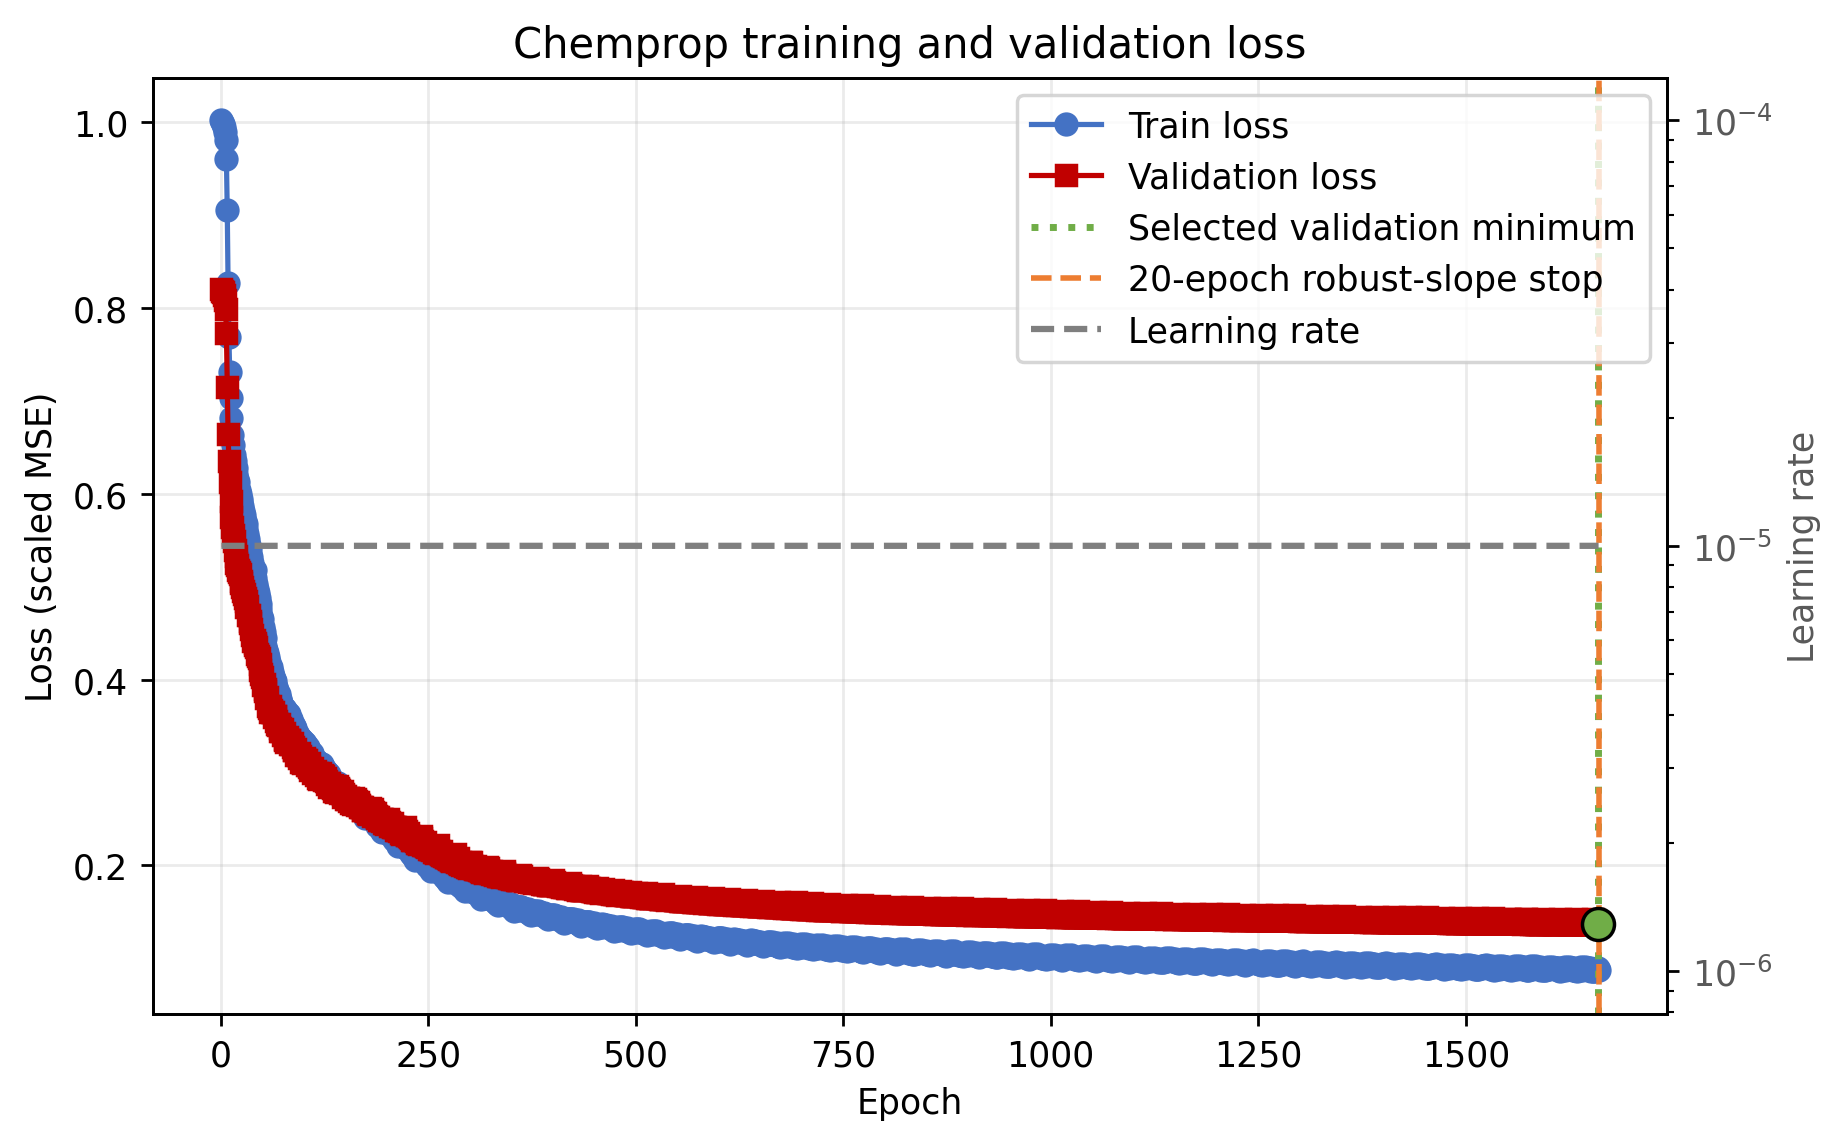

Final model: outputs\bp_chemprop\model_n4600_seed42\segments\segment_83\model_0\best.pt
It is the selected native checkpoint from epoch 1659, where validation loss was lowest among saved eligible segment checkpoints.
Creating train/validation/test predictions...


In [3]:
plot_training_loss(
    loss_history,
    selected_row,
    stopped_by_slope_rule,
    FIGURES / f'loss_vs_epoch_{RUN_TAG}.png',
)
print(f'Final model: {best_model_file}')
print(f'It is the selected native checkpoint from epoch {selected_epoch}, where validation loss was lowest among saved eligible segment checkpoints.')

prediction_file = OUTPUT / f'predictions_{RUN_TAG}.csv'
predict_command = [
    chemprop_executable(), 'predict', '--test-path', str(csv_file), '--smiles-columns', 'SMILES',
    '--model-paths', str(best_model_file), '--preds-path', str(prediction_file),
    '--batch-size', str(BATCH_SIZE), '--num-workers', '0',
]
run_command(predict_command, label='Creating train/validation/test predictions')


**What to notice**

- Compare train, validation, and test MAE/RMSE/R² against a training-mean baseline in kelvin.
- Use common-axis parity plots and best/worst held-out molecules to discuss strengths and failures.
- Save aligned predictions, metrics, architecture settings, and the selected checkpoint path.


,n,MAE (K),RMSE (K),R2
split,,,,
train,3680,10.37,21.14,0.92
val,460,12.65,27.26,0.83
test,460,10.54,18.33,0.93


,n,MAE (K),RMSE (K),R2,Baseline MAE (K),Baseline RMSE (K)
split,,,,,,
train,3680,10.37,21.14,0.92,58.66,73.70
val,460,12.65,27.26,0.83,52.78,66.80
test,460,10.54,18.33,0.93,53.50,66.97


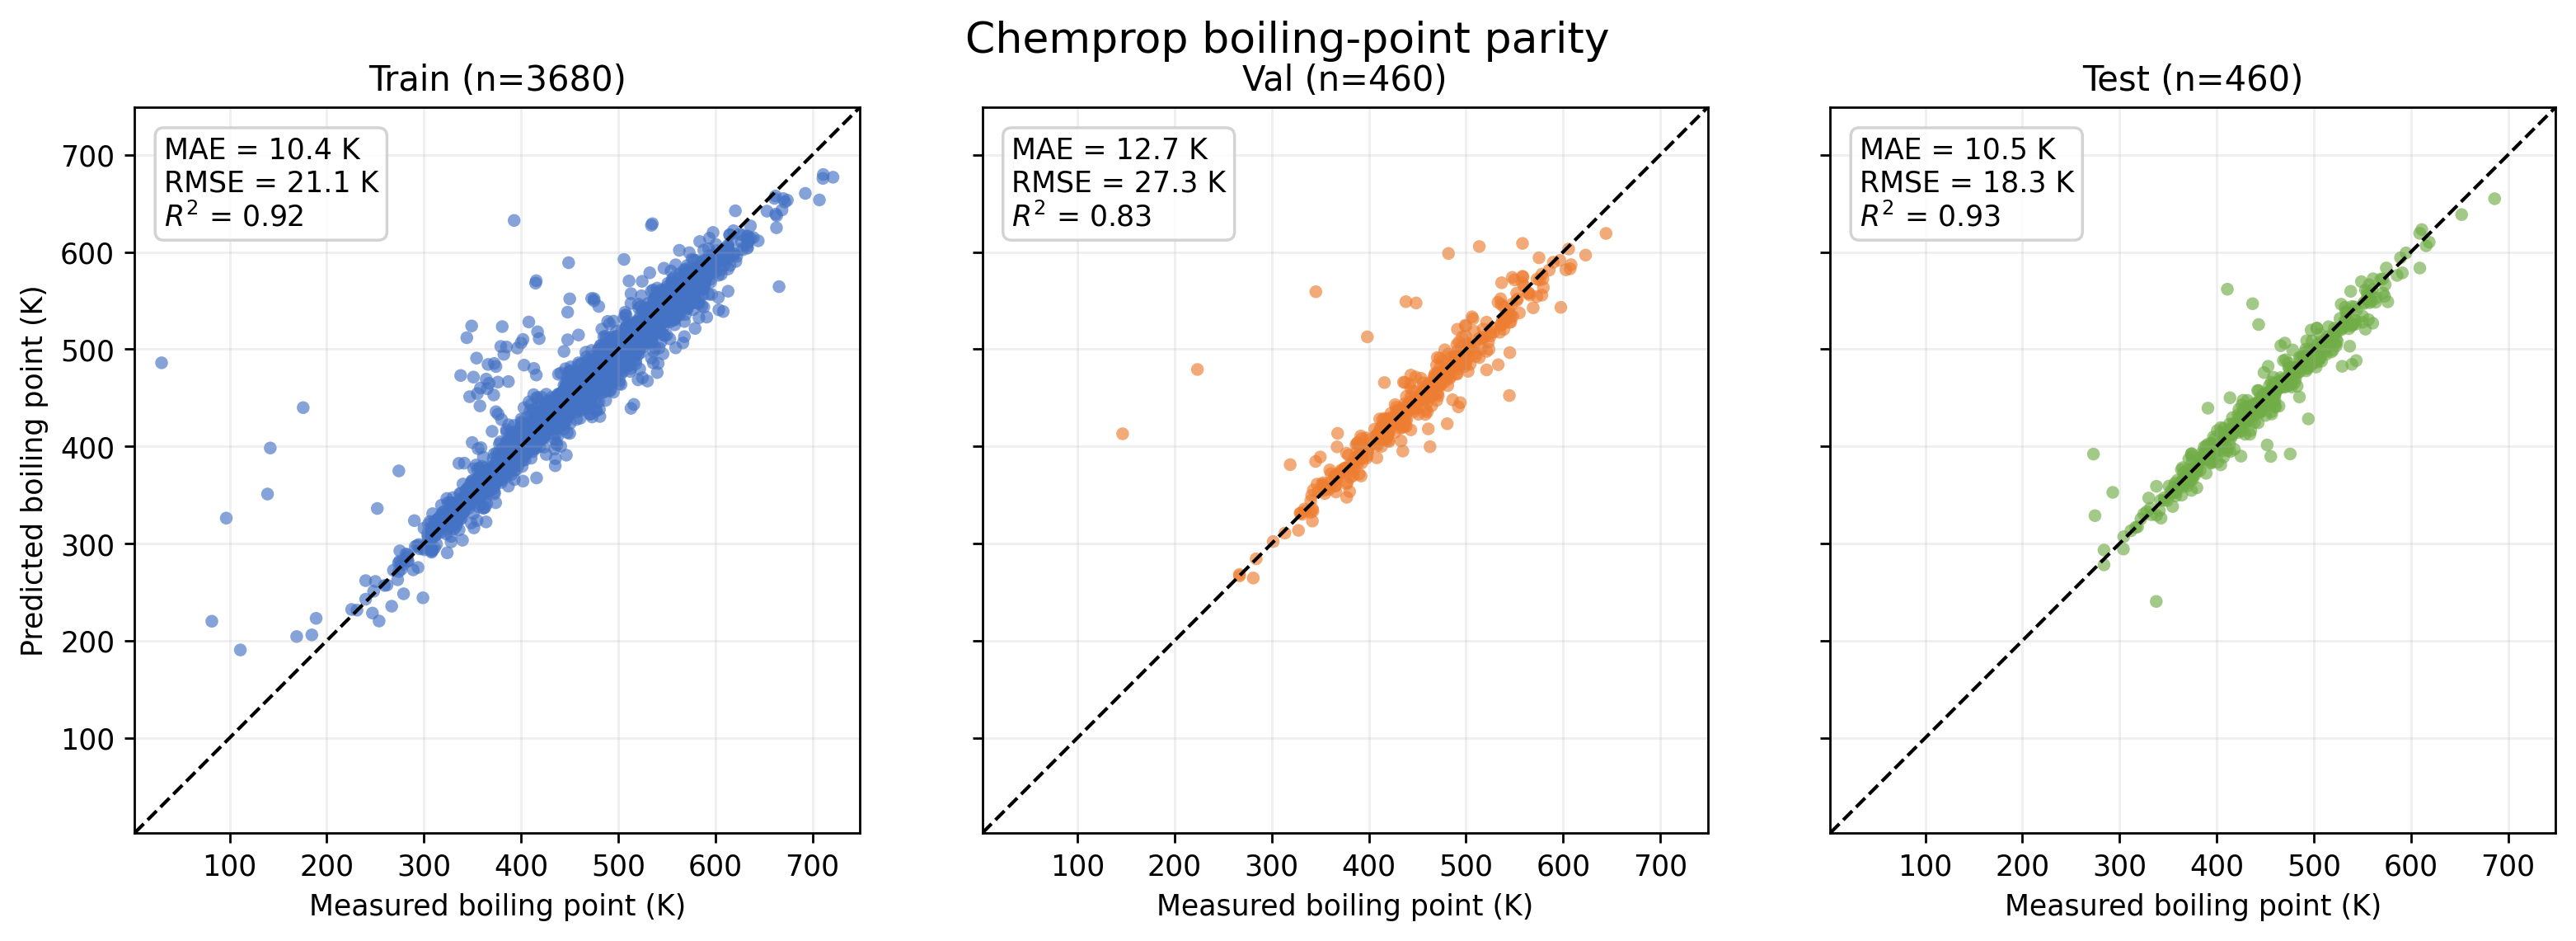

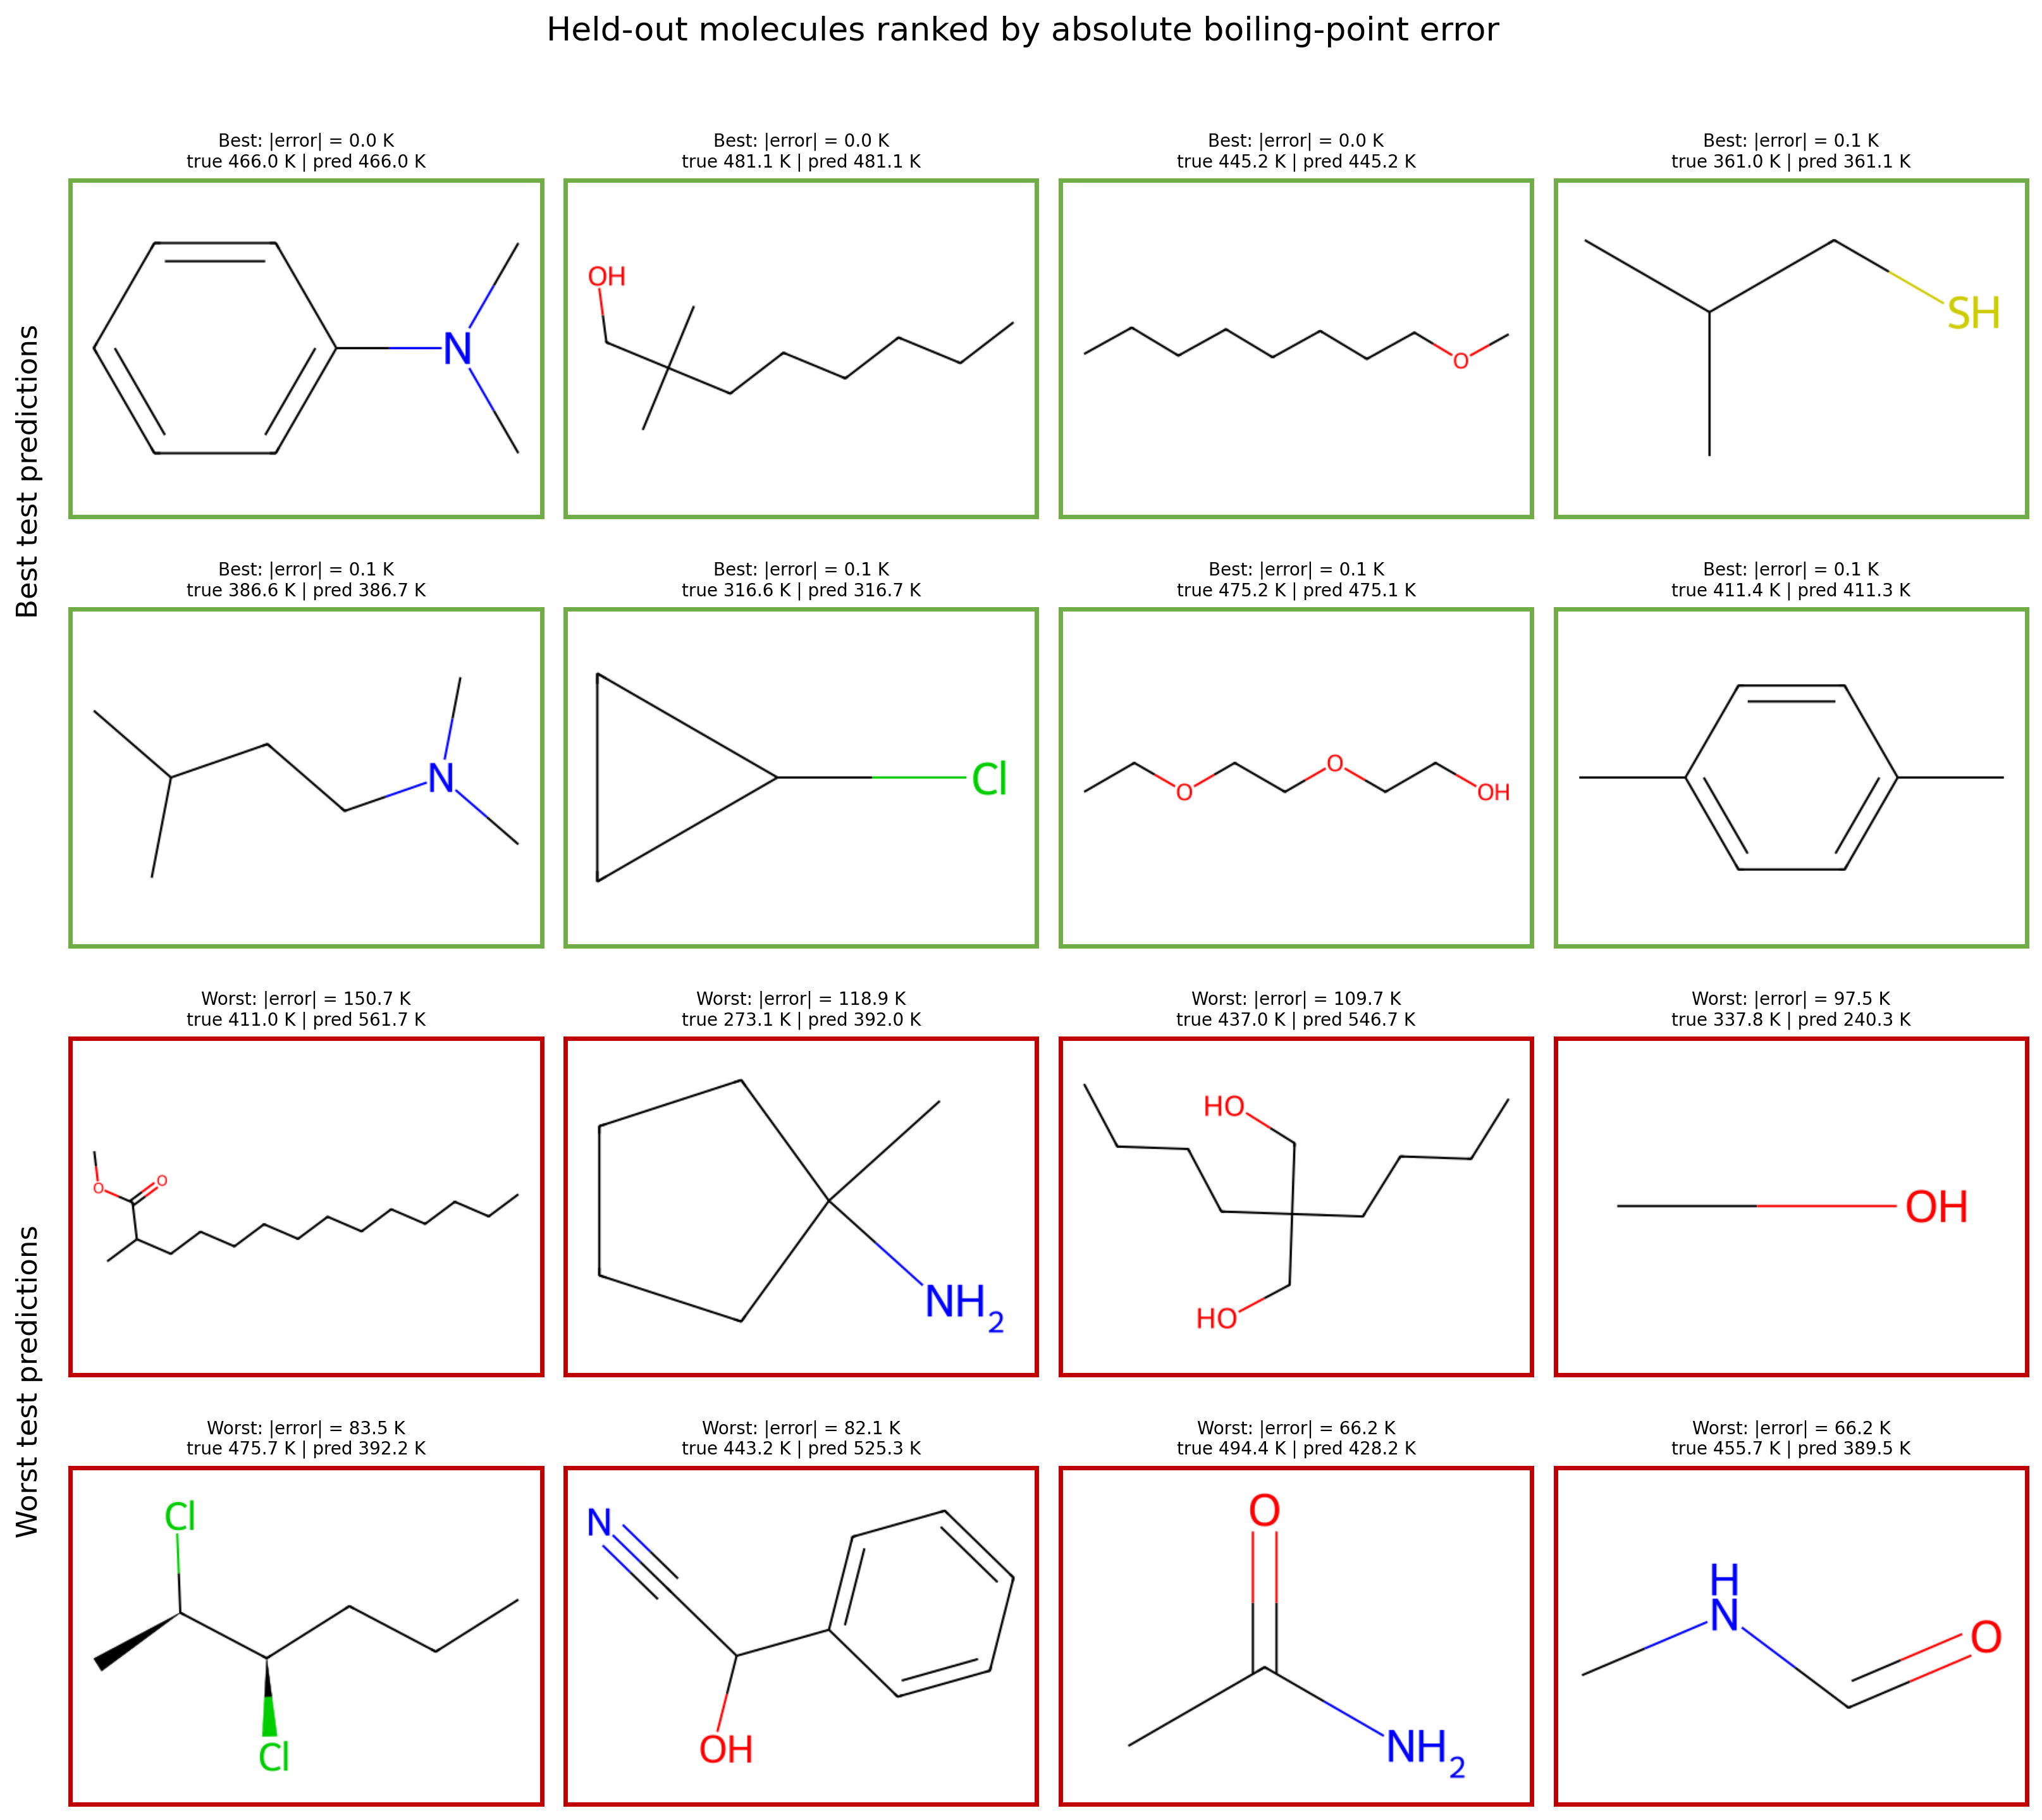

Saved selected model: outputs\bp_chemprop\model_n4600_seed42\segments\segment_83\model_0\best.pt
Saved results and manifest: outputs\bp_chemprop


In [4]:
predictions = pd.read_csv(prediction_file)
candidate_columns = ['BP_pred', 'pred_0', 'BP']
prediction_column = next((column for column in candidate_columns if column in predictions.columns), None)
if prediction_column is None:
    numeric = predictions.select_dtypes(include='number').columns.tolist()
    if len(numeric) != 1:
        raise ValueError(f'Cannot identify prediction column: {predictions.columns.tolist()}')
    prediction_column = numeric[0]

if len(predictions) != len(data):
    raise RuntimeError(f'Prediction/data length mismatch ({len(predictions)} vs {len(data)}). '
                       'Run the configuration, training, review, and evaluation cells in order with one kernel.')

results = data.copy()
results['predicted_BP'] = predictions[prediction_column].to_numpy()
results['residual_K'] = results.BP - results.predicted_BP
results['absolute_error_K'] = results.residual_K.abs()
results.to_csv(OUTPUT / f'BP_predictions_complete_{RUN_TAG}.csv', index=False)

rows = []
for split in ['train', 'val', 'test']:
    subset = results.query('split == @split')
    rows.append({
        'split': split, 'n': len(subset),
        'MAE (K)': mean_absolute_error(subset.BP, subset.predicted_BP),
        'RMSE (K)': mean_squared_error(subset.BP, subset.predicted_BP) ** 0.5,
        'R2': r2_score(subset.BP, subset.predicted_BP),
    })
metrics = pd.DataFrame(rows).set_index('split')
display(metrics.round(2))

baseline_bp = results.query("split == 'train'").BP.mean()
baseline_rows = []
for split in ['train', 'val', 'test']:
    subset = results.query('split == @split')
    baseline_rows.append({'split': split, 'Baseline MAE (K)': mean_absolute_error(subset.BP, np.full(len(subset), baseline_bp)),
                          'Baseline RMSE (K)': mean_squared_error(subset.BP, np.full(len(subset), baseline_bp)) ** 0.5})
baseline_metrics = pd.DataFrame(baseline_rows).set_index('split')
comparison = metrics.join(baseline_metrics)
display(comparison.round(2))

colors = {'train': '#4472C4', 'val': '#ED7D31', 'test': '#70AD47'}
values = np.concatenate([results.BP.to_numpy(), results.predicted_BP.to_numpy()])
padding = 0.04 * (values.max() - values.min())
limits = (values.min() - padding, values.max() + padding)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), sharex=True, sharey=True)
for ax, split in zip(axes, ['train', 'val', 'test']):
    subset = results.query('split == @split')
    ax.scatter(subset.BP, subset.predicted_BP, s=20, alpha=0.65, color=colors[split], edgecolor='none')
    ax.plot(limits, limits, 'k--', linewidth=1.2)
    ax.set(title=f'{split.title()} (n={len(subset)})', xlabel='Measured boiling point (K)', xlim=limits, ylim=limits)
    ax.set_aspect('equal', adjustable='box')
    ax.grid(alpha=0.20)
    row = metrics.loc[split]
    ax.text(0.04, 0.96, f"MAE = {row['MAE (K)']:.1f} K\nRMSE = {row['RMSE (K)']:.1f} K\n$R^2$ = {row['R2']:.2f}",
            transform=ax.transAxes, va='top', bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.85, 'edgecolor': '0.8'})
axes[0].set_ylabel('Predicted boiling point (K)')
fig.suptitle('Chemprop boiling-point parity', fontsize=15)
fig.tight_layout()
parity_figure = FIGURES / f'parity_train_val_test_{RUN_TAG}.png'
fig.savefig(parity_figure, dpi=250, bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(parity_figure)))

def plot_best_and_worst_test_molecules(results, save_path, n_each=8):
    ranked = results.query("split == 'test'").sort_values('absolute_error_K')
    selections = [('Best', row) for _, row in ranked.head(n_each).iterrows()]
    selections += [('Worst', row) for _, row in ranked.tail(n_each).iloc[::-1].iterrows()]
    fig, axes = plt.subplots(4, 4, figsize=(13, 12))
    for ax, (group, row) in zip(axes.flat, selections):
        molecule = Chem.MolFromSmiles(row.SMILES)
        ax.imshow(Draw.MolToImage(molecule, size=(420, 300)))
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{group}: |error| = {row.absolute_error_K:.1f} K\ntrue {row.BP:.1f} K | pred {row.predicted_BP:.1f} K", fontsize=8)
        for spine in ax.spines.values():
            spine.set_edgecolor('#70AD47' if group == 'Best' else '#C00000')
            spine.set_linewidth(2)
    fig.text(0.01, 0.74, 'Best test predictions', rotation=90, va='center', fontsize=13)
    fig.text(0.01, 0.26, 'Worst test predictions', rotation=90, va='center', fontsize=13)
    fig.suptitle('Held-out molecules ranked by absolute boiling-point error', fontsize=15)
    fig.tight_layout(rect=[0.025, 0, 1, 0.965])
    fig.savefig(save_path, dpi=250, bbox_inches='tight')
    plt.close(fig)
    display(Image(filename=str(save_path)))


plot_best_and_worst_test_molecules(results, FIGURES / f'best_worst_test_molecules_{RUN_TAG}.png')

comparison.to_csv(OUTPUT / f'metrics_and_baseline_{RUN_TAG}.csv')
run_manifest = {
    'data_file': str(DATA_FILE), 'rows': len(data), 'seed': SEED, 'versions': VERSIONS,
    'architecture': {'depth': DEPTH, 'message_hidden_dim': MESSAGE_HIDDEN_DIM, 'ffn_hidden_dim': FFN_HIDDEN_DIM, 'ffn_num_layers': FFN_NUM_LAYERS, 'activation': ACTIVATION, 'dropout': DROPOUT},
    'optimization': {'loss': LOSS_FUNCTION, 'optimizer': 'Chemprop default Adam', 'chunk_epochs': CHUNK_EPOCHS, 'max_epochs': MAX_EPOCHS, 'slope_window': VALIDATION_SLOPE_WINDOW, 'trimmed_slope_excluded_points': TRIMMED_SLOPE_EXCLUDED_POINTS, 'warmup_epochs_per_segment': WARMUP_EPOCHS, 'init_lr': INIT_LR, 'max_lr': MAX_LR, 'final_lr': FINAL_LR},
    'selected_model': str(best_model_file), 'selected_epoch': selected_epoch,
    'stopped_by_slope_rule': stopped_by_slope_rule, 'last_raw_validation_slope': raw_slope, 'last_trimmed_validation_slope': trimmed_slope,
    'prediction_file': str(prediction_file), 'metrics': comparison.round(6).reset_index().to_dict(orient='records'),
}
with (OUTPUT / f'run_manifest_{RUN_TAG}.json').open('w', encoding='utf-8') as handle:
    json.dump(run_manifest, handle, indent=2)
print(f'Saved selected model: {best_model_file}')
print(f'Saved results and manifest: {OUTPUT}')


## Discussion

The test panel is the relevant quick-demonstration result. The loss curve identifies the epoch used for the final model: the minimum validation loss. The next notebook asks a complementary question: what can a pretrained molecular language model contribute before task-specific neural-network training.


**What to notice**

- Enter a valid SMILES string, such as CCO for ethanol, and predict with the selected final checkpoint.
- The returned scalar is a boiling point in kelvin; a plausible example is not a substitute for held-out evaluation.


In [6]:
# Predict the boiling point of one new molecule with the selected final model.
# Replace this example SMILES, then run this cell after the training cell above.
SMILES_TO_PREDICT = 'CCO'  # ethanol

if Chem.MolFromSmiles(SMILES_TO_PREDICT) is None:
    raise ValueError(f'Invalid SMILES: {SMILES_TO_PREDICT!r}')
if not best_model_file.exists():
    raise FileNotFoundError('Run the training and model-review cells before predicting a new molecule.')

input_file = OUTPUT / f'new_smiles_input_{RUN_TAG}.csv'
output_file = OUTPUT / f'new_smiles_prediction_{RUN_TAG}.csv'
pd.DataFrame({'SMILES': [SMILES_TO_PREDICT]}).to_csv(input_file, index=False)
run_command([
    chemprop_executable(), 'predict', '--test-path', str(input_file), '--smiles-columns', 'SMILES',
    '--model-paths', str(best_model_file), '--preds-path', str(output_file), '--num-workers', '0',
], label='Predicting boiling point')

prediction = pd.read_csv(output_file)
prediction_column = next((name for name in ['BP_pred', 'pred_0', 'BP'] if name in prediction.columns), None)
if prediction_column is None:
    numeric_columns = prediction.select_dtypes(include='number').columns.tolist()
    if len(numeric_columns) != 1:
        raise ValueError(f'Cannot identify the prediction column: {prediction.columns.tolist()}')
    prediction_column = numeric_columns[0]
print(f'{SMILES_TO_PREDICT}  ->  predicted boiling point: {float(prediction.loc[0, prediction_column]):.1f} K')


Predicting boiling point...
CCO  ->  predicted boiling point: 316.0 K


**What to notice**

- Optional blank practice cell: expand it to add a question or your own follow-up calculation.
- No additional analysis is implemented in this cell.
